Name: Punit Bhokare         
Roll No. : 08
CSE(DS)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
%pip install kagglehub

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [3]:
import kagglehub
import os

path = kagglehub.dataset_download("arezaei81/heartcsv")

for root, dirs, files in os.walk(path):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.join(root, file))

C:\Users\Asus\.cache\kagglehub\datasets\arezaei81\heartcsv\versions\1\heart.csv


In [4]:
import os

csv_file = next(
    os.path.join(root, file)
    for root, dirs, files in os.walk(path)
    for file in files
    if file.endswith(".csv")
)

df = pd.read_csv(csv_file)

print("Dataset Shape:", df.shape)
display(df.head())
print(df.info())

Dataset Shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB
None


In [5]:
print("Missing Values:\n", df.isnull().sum())
print("\nDuplicate Rows:", df.duplicated().sum())

df = df.drop_duplicates()

X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Missing Values:
 age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Duplicate Rows: 1
Training Data: (241, 13)
Testing Data: (61, 13)


In [6]:
dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

y_pred = dt_model.predict(X_test)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


In [7]:
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.8197
Precision: 0.75
Recall: 1.0
F1 Score: 0.8571

Classification Report:

              precision    recall  f1-score   support

           0       1.00      0.61      0.76        28
           1       0.75      1.00      0.86        33

    accuracy                           0.82        61
   macro avg       0.88      0.80      0.81        61
weighted avg       0.86      0.82      0.81        61



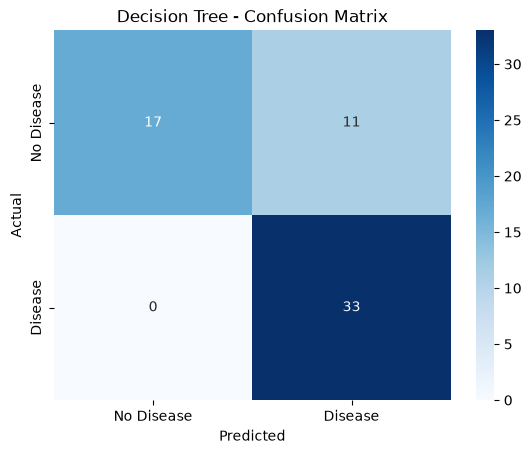

In [8]:

cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Disease", "Disease"],
            yticklabels=["No Disease", "Disease"])

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree - Confusion Matrix")
plt.show()


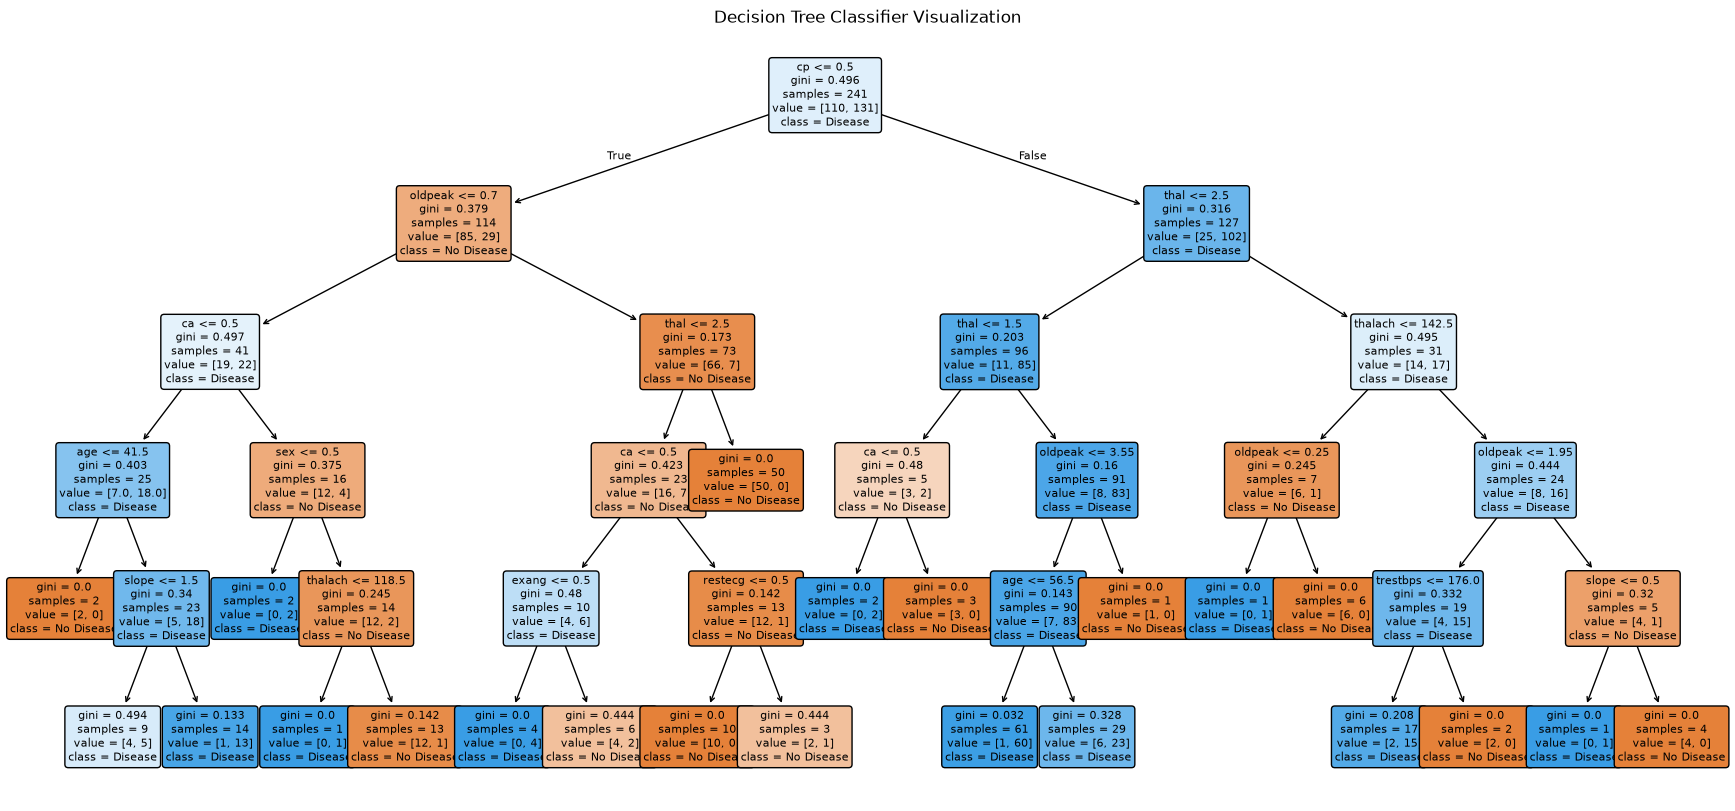

In [9]:

plt.figure(figsize=(22, 10))

plot_tree(
    dt_model,
    feature_names=X.columns,
    class_names=["No Disease", "Disease"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree Classifier Visualization")
plt.show()


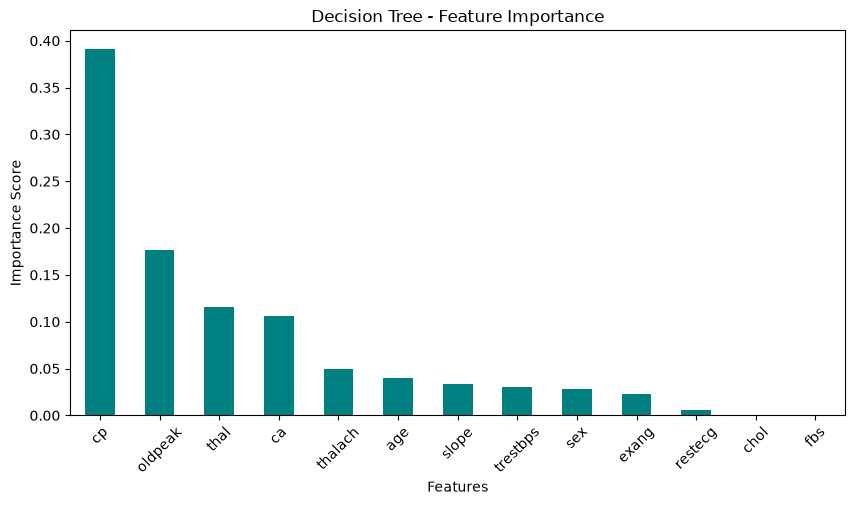

In [10]:

importance = pd.Series(
    dt_model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

importance.plot(kind="bar", figsize=(10, 5), color="teal")

plt.title("Decision Tree - Feature Importance")
plt.xlabel("Features")
plt.ylabel("Importance Score")
plt.xticks(rotation=45)
plt.show()


In [11]:

print("Decision Tree Algorithm Analysis Completed Successfully.")
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")
print("F1 Score:", round(f1_score(y_test, y_pred), 4))


Decision Tree Algorithm Analysis Completed Successfully.
Accuracy: 81.97 %
F1 Score: 0.8571
